In [192]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# csv input paths
baseline_input_path = "csv_baseline/all_combined_metrics.csv"
first_pass_input_path = "csv_first_pass/all_combined_metrics.csv"
second_pass_input_path = "csv_full_evaluation/all_combined_metrics.csv"
# benchmarking

# csv output paths
baseline_output_path = "csv_edited/all_combined_metrics_BASELINE.csv"
first_pass_output_path = "csv_edited/all_combined_metrics_FIRST_PASS.csv"
second_pass_output_path = "csv_edited/all_combined_metrics_SECOND_PASS.csv"

combined_df_path = "csv_edited/all_results_from_all_runs.csv"
combined_df_path_sorted = "csv_edited/all_results_from_all_runs_SORTED.csv"

metrics = ["Hit@K", "MRR", "BLEU", "ROUGE", "METEOR", "Groundedness", "Answer_Relevance", "Context_Relevance", "Avg_Time(s)"]
scaler = MinMaxScaler()

weighting = {
    "Hit@K" : 0.25, 
    "MRR" : 0.05, 
    "BLEU" : 0.05, 
    "ROUGE" : 0.05, 
    "METEOR" : 0.05, 
    "Groundedness" : 0.25, 
    "Answer_Relevance" : 0.1, 
    "Context_Relevance" : 0.1, 
    "Avg_Time(s)" : -0.1
}


In [172]:
def load_and_normalise(input_file_path):
    df = pd.read_csv(input_file_path)
    normalised_data = scaler.fit_transform(df[metrics])
    normalised_data = pd.DataFrame(normalised_data)
    normalised_data.columns = metrics
    return df, normalised_data

In [173]:
# sort values and export to csv
def sort_and_export(df, normalised_data, out_file_path):
    weight_s = pd.Series(weighting)
    cols = [c for c in weight_s.index if c in normalised_data.columns]

    normalised_data["score"] = normalised_data[cols].dot(weight_s[cols])

    df_combined = pd.concat([df, normalised_data["score"]], axis=1)

    sorted_df = df_combined.sort_values(by="score", ascending=False)
    sorted_df = sorted_df.fillna(0)
    sorted_df.to_csv(out_file_path, index=True)

    return sorted_df

In [ ]:
def plot_results(df, title):
    fig = plt.figure(figsize=(12, 12))
    plot3d = fig.add_subplot(111, projection="3d")

    x = df["Groundedness"]
    y = df["Avg_Time(s)"]
    z = df["score"]

    plot3d.scatter(x, y, z, c=z, cmap="viridis", s=80, edgecolors="black")


    for df_idx, xv, yv, zv in zip(df.index, x, y, z):
        plot3d.text(xv, yv, zv + 0.02, str(df_idx), fontsize=9, ha="center", va="bottom")

    # uncomment this to label only the top score
    # for df_idx, xv, yv, zv in zip(df.index, x, y, z):
    #     if df_idx == 302:
    #         plot3d.text(xv, yv, zv + 0.02, str(df_idx), fontsize=9, ha="center", va="bottom")

    for xv, yv, zv in zip(x, y, z):
        plot3d.plot([xv, xv], [yv, yv], [0, zv], color="gray", alpha=0.5, linewidth=1)

    plot3d.set_xlabel("Groundedness")
    plot3d.set_ylabel("Avg_Time(s)")
    plot3d.set_zlabel("Score")

    plot3d.set_title(title)

    plot3d.set_proj_type("ortho") 
    plot3d.set_box_aspect([1, 1, 1])
    plot3d.view_init(elev=30, azim=45)

    plt.show()

In [175]:
# process baseline results
df_baseline, normalised_data = load_and_normalise(baseline_input_path)
df_bl_sorted = sort_and_export(df_baseline, normalised_data, baseline_output_path)
df_bl_sorted

,Unnamed: 0.1,Unnamed: 0,Hit@K,MRR,BLEU,ROUGE,METEOR,Groundedness,Answer_Relevance,Context_Relevance,...,num_io_workers,cache_answers,pre_compute_captions,use_reranker,reranker_model,reranker_batch_size,use_rewriter,rewriter_model,domain_hints,score
2,0,0,1.0,0.2237,0.0832,0.2900,0.1582,0.9833,0.4991,0.8500,...,8,True,True,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.757563
0,0,0,1.0,0.2237,0.0103,0.2893,0.1472,1.0000,0.5352,0.8333,...,8,True,True,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.617294
1,0,0,0.0,0.0100,0.1091,0.1931,0.1675,0.3500,0.6776,0.2000,...,8,True,True,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.108752


In [189]:
# process first-pass results
df_first_pass, normalised_data = load_and_normalise(first_pass_input_path)
df_fp_sorted = sort_and_export(df_first_pass, normalised_data, first_pass_output_path)
df_fp_sorted

,Unnamed: 0,Hit@K,MRR,BLEU,ROUGE,METEOR,Groundedness,Answer_Relevance,Context_Relevance,Avg_Time(s),...,num_io_workers,cache_answers,pre_compute_captions,use_reranker,reranker_model,reranker_batch_size,use_rewriter,rewriter_model,domain_hints,score
23,23,1,0.2237,0.1026,0.3193,0.1719,0.9500,0.5721,0.8333,0.52,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.817651
3,3,1,0.2237,0.0047,0.3133,0.1468,1.0000,0.5280,0.8667,3.01,...,8,True,False,True,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.753603
20,20,1,0.2237,0.0038,0.2522,0.1365,1.0000,0.5182,0.8500,0.54,...,8,True,True,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.748413
19,19,1,0.2237,0.0769,0.2209,0.2688,0.7167,0.6651,0.8667,2.91,...,8,True,True,True,cross-encoder/ms-marco-MiniLM-L-6-v2,32,True,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.742448
13,13,1,0.2237,0.0054,0.2834,0.1396,1.0000,0.4942,0.8667,2.39,...,8,True,True,True,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.739235
4,4,1,0.2237,0.0127,0.2882,0.1446,0.9667,0.5643,0.8667,8.26,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.717013
9,9,1,0.2237,0.0518,0.2664,0.1445,0.9667,0.4705,0.8667,8.45,...,8,True,True,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.700891
5,5,1,0.2237,0.0579,0.1634,0.2584,0.7167,0.5738,0.8667,1.89,...,8,True,True,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,True,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.696039
2,2,1,0.2237,0.0055,0.2886,0.1414,1.0000,0.5263,0.8667,13.84,...,8,True,False,True,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.675771
6,6,1,0.2237,0.0935,0.2004,0.2798,0.7000,0.4529,0.8000,1.56,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,True,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.675762


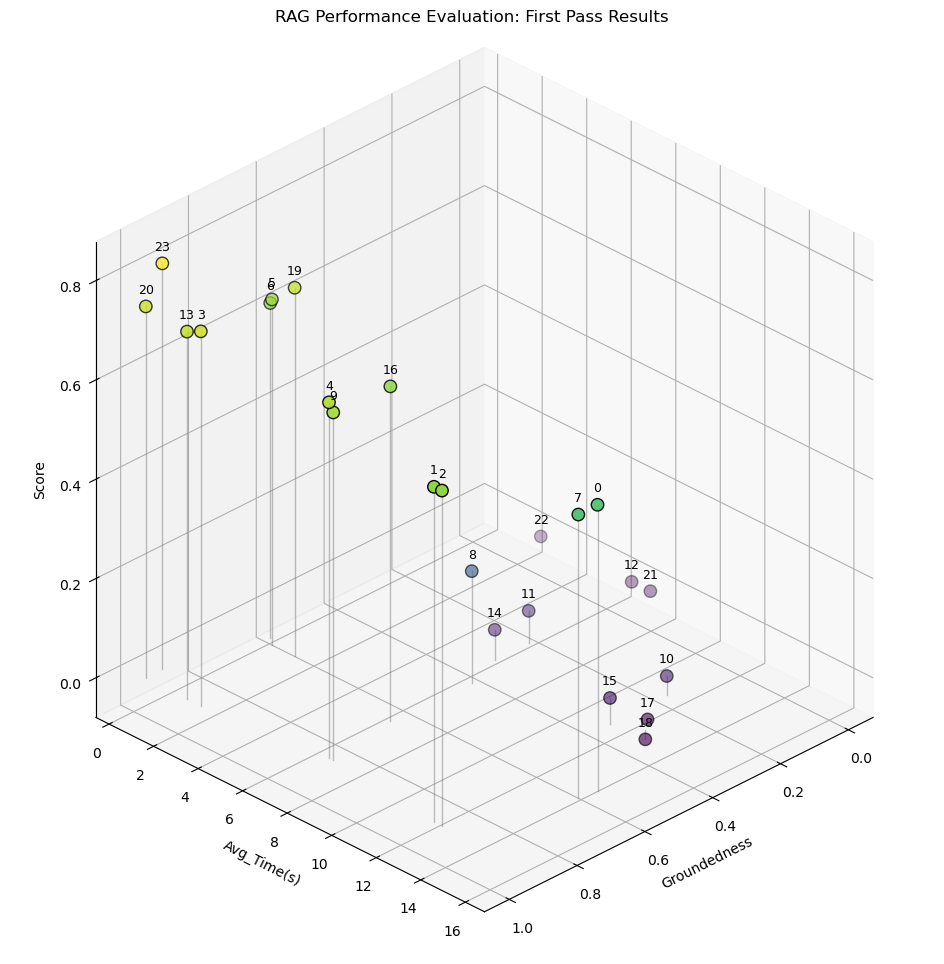

In [177]:
# visualising first pass results
plot_results(df_fp_sorted, "RAG Performance Evaluation: First Pass Results")

In [196]:
# process second-pass results
df_second_pass, normalised_data = load_and_normalise(second_pass_input_path)
df_sp_sorted = sort_and_export(df_second_pass, normalised_data, second_pass_output_path)
df_sp_sorted

,Unnamed: 0.1,Unnamed: 0,Hit@K,MRR,BLEU,ROUGE,METEOR,Groundedness,Answer_Relevance,Context_Relevance,...,num_io_workers,cache_answers,pre_compute_captions,use_reranker,reranker_model,reranker_batch_size,use_rewriter,rewriter_model,domain_hints,score
302,0,0,1.0,0.2237,0.0269,0.3354,0.1671,1.0000,0.5860,0.8667,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,0,0.512951
395,0,0,1.0,0.2237,0.0295,0.3379,0.1736,1.0000,0.5215,0.8333,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.439302
309,0,0,1.0,0.2237,0.0770,0.3268,0.1654,0.9833,0.5563,0.8333,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.434214
397,0,0,1.0,0.2237,0.0581,0.3178,0.1579,1.0000,0.4699,0.8667,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,0,0.430361
315,0,0,1.0,0.2237,0.0829,0.3375,0.1732,0.9833,0.5277,0.8333,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,0,0.428960
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
468,0,0,1.0,0.2237,0.0100,0.3147,0.1487,0.9167,0.4735,0.8000,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.154830
142,0,0,1.0,0.2237,0.0578,0.3218,0.1655,0.9000,0.4675,0.8000,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,0,0.138772
379,0,0,1.0,0.2237,0.0061,0.3147,0.1487,0.9167,0.4325,0.8000,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.129117
234,0,0,1.0,0.2237,0.0625,0.3230,0.1587,0.8833,0.4683,0.8000,...,8,True,False,False,cross-encoder/ms-marco-MiniLM-L-6-v2,32,False,zorowin123/rq_rag_llama2_7B,"architecture, architectural design, buildings,...",0.127451


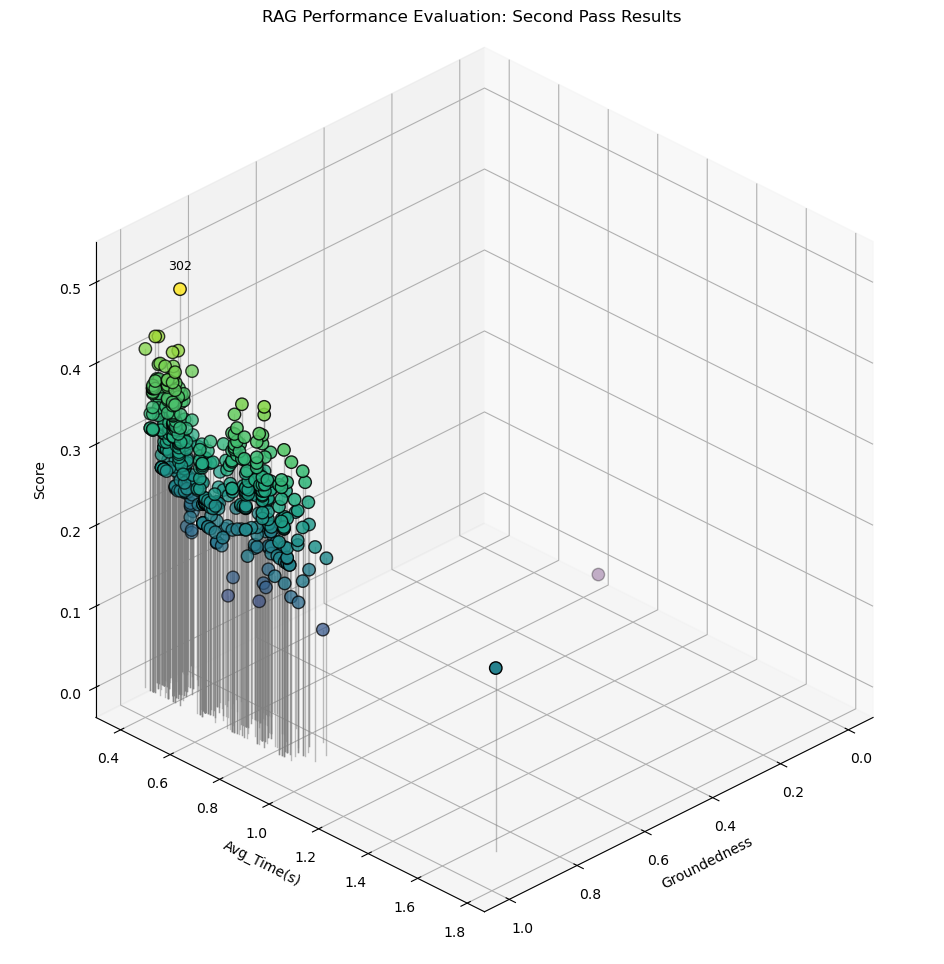

In [183]:
# visualising second pass results
plot_results(df_sp_sorted, "RAG Performance Evaluation: Second Pass Results")

In [193]:
# # create a combined dataset for standardisation of data normalisation
# combined_df = pd.concat([df_baseline, df_first_pass, df_second_pass])
# combined_df.to_csv(combined_df_path, index=False)
# # process all results
# combined_df_norm, normalised_data = load_and_normalise(combined_df_path)
# combined_df_sorted = sort_and_export(combined_df_path, normalised_data, combined_df_path_sorted)
# combined_df_sorted.head()

TypeError: cannot concatenate object of type '<class 'str'>'; only Series and DataFrame objs are valid